# Readmission Pipeline (Student Project)

Goal: Predict 30-day readmission from hospital encounter data.

Workflow layers:
1. Raw Data
2. Data Understanding (EDA)
3. Data Cleaning
4. Feature Engineering
5. Modeling
6. Saved Artifact (.joblib)


In [75]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Layer 1 — Raw Data (Input)
Load the raw CSV without changing it.


In [76]:
raw_path = '../data/raw/diabetic_data.csv'
df_raw = pd.read_csv(raw_path)
df_raw.head()


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Layer 2 — Data Understanding (EDA)
Answer: is the target learnable? which columns are noise? how is missingness encoded?


In [77]:
df_raw.shape


(101766, 50)

In [78]:
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [79]:
# target distribution
df_raw['readmitted'].value_counts()


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [80]:
df_raw['readmitted'].value_counts(normalize=True)


readmitted
NO     0.539119
>30    0.349282
<30    0.111599
Name: proportion, dtype: float64

In [81]:
# uniqueness check (identify IDs / zero-variance)
df_raw.nunique().sort_values(ascending=False).head(10)


encounter_id          101766
patient_nbr            71518
diag_3                   790
diag_2                   749
diag_1                   717
num_lab_procedures       118
num_medications           75
medical_specialty         73
number_outpatient         39
number_emergency          33
dtype: int64

In [82]:
# check for constant columns
df_raw.nunique().sort_values().head(10)


citoglipton                 1
examide                     1
troglitazone                2
change                      2
metformin-pioglitazone      2
metformin-rosiglitazone     2
glimepiride-pioglitazone    2
glipizide-metformin         2
acetohexamide               2
tolbutamide                 2
dtype: int64

In [83]:
# how missingness is encoded
(df_raw == '?').sum().sort_values(ascending=False).head(10)


weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
encounter_id             0
tolazamide               0
glyburide                0
dtype: int64

In [84]:
# age ranges
df_raw['age'].value_counts(dropna=False).head(10)


age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

In [85]:
# sample of diagnosis codes
df_raw[['diag_1','diag_2','diag_3']].head()


,diag_1,diag_2,diag_3
0,250.83,?,?
1,276,250.01,255
2,648,250,V27
3,8,250.43,403
4,197,157,250


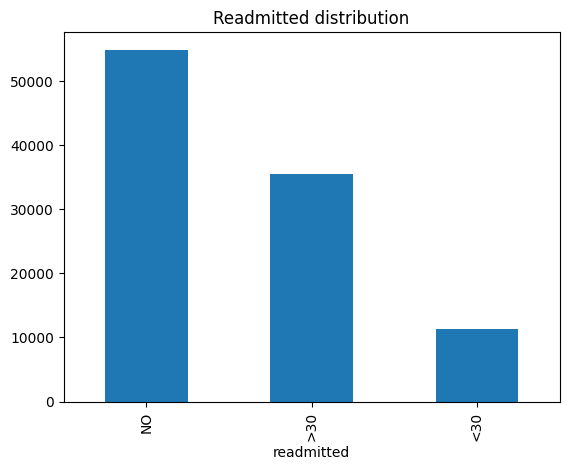

In [86]:
# quick plot of readmitted distribution
df_raw['readmitted'].value_counts().plot(kind='bar')
plt.title('Readmitted distribution')
plt.show()


## Layer 3 — Data Cleaning
Make the data trustworthy (structural fixes).


In [87]:
df = df_raw.copy()
# replace '?' placeholders
df = df.replace('?', np.nan)

# fix illegal values
if 'race' in df.columns:
    df['race'] = df['race'].replace('0', np.nan)

# drop duplicates
df = df.drop_duplicates()

# drop identifier columns (leakage risk)
id_cols = ['encounter_id', 'patient_nbr']
df = df.drop(columns=[c for c in id_cols if c in df.columns])

df.isna().sum().sort_values(ascending=False).head(10)


weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
tolbutamide              0
dtype: int64

## Layer 4 — Feature Engineering
Convert clinical concepts into model-friendly features.


In [88]:
# target: readmitted within 30 days
df['readmit_binary'] = (df['readmitted'] == '<30').astype(int)
df['readmit_binary'].value_counts()


readmit_binary
0    90409
1    11357
Name: count, dtype: int64

In [90]:
# age bins to numeric midpoint

def age_to_num(age_range):
    if pd.isna(age_range):
        return np.nan
    
    s = str(age_range).strip('[]()')  # remove [, ], (, )
    
    if '-' in s:
        lo, hi = s.split('-')
        return (int(lo) + int(hi)) / 2
    
    return np.nan

df['age_num'] = df['age'].apply(age_to_num)
df[['age','age_num']].head()


,age,age_num
0,[0-10),5.0
1,[10-20),15.0
2,[20-30),25.0
3,[30-40),35.0
4,[40-50),45.0


In [91]:
# ICD-9 grouping (simple)
def group_icd(code):
    if pd.isna(code):
        return 'Unknown'
    code = str(code)
    if code.startswith(('V','E')):
        return 'Other'
    try:
        x = float(code)
    except:
        return 'Other'
    if 1 <= x <= 139: return 'Infectious'
    if 140 <= x <= 239: return 'Neoplasms'
    if 240 <= x <= 279: return 'Endocrine'
    if 280 <= x <= 289: return 'Blood'
    if 290 <= x <= 319: return 'Mental'
    if 320 <= x <= 389: return 'Nervous'
    if 390 <= x <= 459: return 'Circulatory'
    if 460 <= x <= 519: return 'Respiratory'
    if 520 <= x <= 579: return 'Digestive'
    if 580 <= x <= 629: return 'Genitourinary'
    if 630 <= x <= 679: return 'Pregnancy'
    if 680 <= x <= 709: return 'Skin'
    if 710 <= x <= 739: return 'Musculoskeletal'
    if 740 <= x <= 759: return 'Congenital'
    if 760 <= x <= 779: return 'Perinatal'
    if 780 <= x <= 799: return 'Symptoms'
    if 800 <= x <= 999: return 'Injury'
    return 'Other'

for c in ['diag_1','diag_2','diag_3']:
    if c in df.columns:
        df[c + '_grp'] = df[c].apply(group_icd)

df[['diag_1','diag_1_grp']].head()


,diag_1,diag_1_grp
0,250.83,Endocrine
1,276,Endocrine
2,648,Pregnancy
3,8,Infectious
4,197,Neoplasms


In [92]:
# fill missing categoricals with 'Unknown'
cat_cols = df.select_dtypes(include=['object']).columns
for c in cat_cols:
    df[c] = df[c].fillna('Unknown')

df[cat_cols].isna().sum().sum()


np.int64(0)

In [93]:
# drop raw diagnosis codes and raw age bins
drop_raw = ['diag_1','diag_2','diag_3','age']
df = df.drop(columns=[c for c in drop_raw if c in df.columns])

# drop known zero-variance columns if present
zero_var = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
df = df.drop(columns=zero_var)

df.head()


,race,gender,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,...,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmit_binary,age_num,diag_1_grp,diag_2_grp,diag_3_grp
0,Caucasian,Female,Unknown,6,25,1,1,Unknown,Pediatrics-Endocrinology,41,...,No,No,No,No,NO,0,5.0,Endocrine,Unknown,Unknown
1,Caucasian,Female,Unknown,1,1,7,3,Unknown,Unknown,59,...,No,No,Ch,Yes,>30,0,15.0,Endocrine,Endocrine,Endocrine
2,AfricanAmerican,Female,Unknown,1,1,7,2,Unknown,Unknown,11,...,No,No,No,Yes,NO,0,25.0,Pregnancy,Endocrine,Other
3,Caucasian,Male,Unknown,1,1,7,2,Unknown,Unknown,44,...,No,No,Ch,Yes,NO,0,35.0,Infectious,Endocrine,Circulatory
4,Caucasian,Male,Unknown,1,1,7,1,Unknown,Unknown,51,...,No,No,Ch,Yes,NO,0,45.0,Neoplasms,Neoplasms,Endocrine


In [95]:
# remove very high-missing columns (student choice)
drop_missing = ['weight', 'medical_specialty', 'payer_code']
df = df.drop(columns=[c for c in drop_missing if c in df.columns])

df.isna().sum().sort_values(ascending=False).head(10)


race                   0
gender                 0
pioglitazone           0
rosiglitazone          0
acarbose               0
miglitol               0
troglitazone           0
tolazamide             0
insulin                0
glyburide-metformin    0
dtype: int64

## Layer 5 — Modeling
Split data, build preprocessing + model pipeline, evaluate.


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score, f1_score, roc_auc_score

target = 'readmit_binary'
X = df.drop(columns=[target, 'readmitted'])
y = df[target]

# treat these numeric-looking IDs as categoricals
force_categorical = [
    'admission_type_id','discharge_disposition_id','admission_source_id'
]

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
for c in force_categorical:
    if c in X.columns and c not in cat_cols:
        cat_cols.append(c)

num_cols = [c for c in X.columns if c not in cat_cols]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
    ,('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocess = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols),
    ]
)

clf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=1000))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:,1]

print('Accuracy:', accuracy_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))
print('ROC-AUC:', roc_auc_score(y_test, y_prob))
print('Confusion matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification report:\n', classification_report(y_test, y_pred))


/Users/lokesh/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.8882774884543578
Recall: 0.015852047556142668
F1: 0.030690537084398978
ROC-AUC: 0.6756539205819206
Confusion matrix:
 [[18044    39]
 [ 2235    36]]
Classification report:
               precision    recall  f1-score   support

           0       0.89      1.00      0.94     18083
           1       0.48      0.02      0.03      2271

    accuracy                           0.89     20354
   macro avg       0.68      0.51      0.49     20354
weighted avg       0.84      0.89      0.84     20354



## Layer 6 — Save the Pipeline
Save the full preprocessing + model pipeline as a .joblib.


In [53]:
import joblib
model_path = '../models/readmission_pipeline.joblib'
joblib.dump(clf, model_path)
model_path


'../models/readmission_pipeline.joblib'